# 10 新加坡资产：ES3.SI（SPDR STI ETF）GARCH 波动率目标 + A35.SI 债券

**思路**：收益方向难以预测，但波动率可以预测（波动聚集）。用 GARCH 预测 ES3 明天的波动，
ES3 仓位 `w = min(目标波动 / 预测波动, 上限)`：预测波动大就少持，小就多持；
**剩余 1 − w 持有 A35.SI（ABF Singapore Bond Index Fund，新加坡政府债为主）**，不持现金。

> 持有债券后，"组合波动 = w × ES3 波动"只是近似（还要加上债券自身波动和股债相关性），
> 因债券波动远低于股票，近似误差很小；`sti_bond_stats` 表报告了 A35 波动与股债相关性供核对。
> 对照组"固定比例 ES3/A35"把 ES3 仓位固定为 GARCH 策略样本内的平均仓位，用来区分
> 收益来自"多了债券"还是来自"GARCH 择时"。

| 步骤 | 内容 |
|---|---|
| ① | ARCH 效应检验：收益与收益平方的 Ljung-Box、Engle ARCH-LM |
| ② | 样本内（≤ 2019）估计 GARCH(1,1)-Normal / GARCH(1,1)-t / GJR-GARCH(1,1)-t，按 BIC 选模型 |
| ③ | 残差诊断：标准化残差及其平方的 Ljung-Box |
| ④ | 样本外（2020 起）波动预测评估：对比 EWMA(0.94) 与 20 日滚动；MSE / QLIKE 与 Diebold-Mariano 检验 |
| ⑤ | Mincer-Zarnowitz 回归：`r²_{t+1} = a + b·σ̂²_{t+1} + e`，Newey-West 标准误，检验 a=0、b=1 |
| ⑥ | 策略回测：GARCH+A35（主方案）对比 GARCH+现金、EWMA/滚动+A35、固定比例 ES3/A35、买入持有 ES3、买入持有 A35；分块 bootstrap 检验 Sharpe 差异 |

**成交与无前视约定**（与主策略一致）：T 日收盘后用截至 T 日的数据预测 T+1 波动并定仓位，T+1 开盘调仓；
隔夜收益（T 收盘→T+1 开盘）归属旧仓位，日内收益（开盘→收盘）归属新仓位。ES3 与 A35 单边成本默认各 10 bps，调仓时两边都收费；现金收益为 0。

**样本外参数**：默认 `REFIT='monthly'`，每月初只用此前的数据（扩展窗口）重新估计一次参数；
`REFIT=None` 则冻结样本内参数。

**数据**：首次运行把最后一格 `DOWNLOAD` 改为 `True`（需 `pip install yfinance`），
下载 ES3.SI、A35.SI 与 USD/SGD 汇率到 `data/raw/sti_daily.csv`，之后改回 `False`。
（旧版 CSV 没有 A35 列时，会提示重新下载，并暂时以现金代替债券运行。）
`BASE_CCY='USD'` 时价格按当日 USD/SGD 收盘汇率折算为美元（开盘价也用当日收盘汇率，属近似）。

输出：`results/tables/sti_*.csv`、`results/figures/sti_*.png`、`results/signals/sti_latest_weight.csv`。

In [23]:
from pathlib import Path
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from arch import arch_model
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch


def find_project_root():
    """支持从项目根目录、pipeline 目录及项目内子目录启动。"""
    roots = ([Path(os.environ['ETF_PROJECT_ROOT']).expanduser()] if os.environ.get('ETF_PROJECT_ROOT') else [])
    roots += [Path.cwd(), *Path.cwd().parents]
    for root in roots:
        if (root / 'pipeline' / '00_engine.ipynb').is_file():
            return root.resolve()
    raise FileNotFoundError('找不到项目根目录（应包含 pipeline/00_engine.ipynb）。请设置 ETF_PROJECT_ROOT。')


ROOT = find_project_root()
PIPELINE_DIR = ROOT / 'pipeline'


def load_notebook_definitions(filename):
    """独立命名空间加载函数；不执行被加载 notebook 的入口单元格。"""
    path = PIPELINE_DIR / filename
    notebook = json.loads(path.read_text(encoding='utf-8'))
    namespace = {'__name__': 'pipeline_module'}
    for number, item in enumerate(notebook['cells']):
        if item['cell_type'] == 'code' and 'pipeline-entry' not in item.get('metadata', {}).get('tags', []):
            exec(compile(''.join(item['source']), f'{path}:cell{number}', 'exec'), namespace)
    return namespace


# 与主策略共用样本划分和绩效指标，保证口径一致
_engine = load_notebook_definitions('00_engine.ipynb')
IS_START = _engine['IS_START']
IS_END = _engine['IS_END']
OOS_START = _engine['OOS_START']
metrics = _engine['metrics']
fmt = _engine['fmt']

TICKER = 'ES3.SI'      # SPDR STI ETF
BOND_TICKER = 'A35.SI' # ABF Singapore Bond Index Fund
FX_TICKER = 'SGD=X'    # USD/SGD：1 美元兑多少新元
SLEEVE_WEIGHT = 0.10   # 新加坡部分在总组合中的比例（用于输出总组合仓位）
STI_CSV = ROOT / 'data' / 'raw' / 'sti_daily.csv'
TABLE_DIR = ROOT / 'results' / 'tables'
FIG_DIR = ROOT / 'results' / 'figures'
SIGNAL_DIR = ROOT / 'results' / 'signals'

MODEL_SPECS = {
    'GARCH(1,1)-Normal': dict(vol='GARCH', p=1, o=0, q=1, dist='normal'),
    'GARCH(1,1)-t':      dict(vol='GARCH', p=1, o=0, q=1, dist='t'),
    'GJR-GARCH(1,1)-t':  dict(vol='GARCH', p=1, o=1, q=1, dist='t'),
}
EWMA_LAMBDA = 0.94     # RiskMetrics
ROLL_WINDOW = 20

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'PingFang SC', 'Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

## 0. 数据：下载与读取

In [24]:
def _flatten(df):
    if isinstance(df.columns, pd.MultiIndex):
        df = df.copy()
        df.columns = df.columns.get_level_values(0)
    return df


def _ohlc_frame(px, prefix=''):
    return pd.DataFrame({
        f'{prefix}open': px['Open'], f'{prefix}high': px['High'], f'{prefix}low': px['Low'],
        f'{prefix}close': px['Close'], f'{prefix}adj_close': px['Adj Close'], f'{prefix}volume': px['Volume'],
    })


def download_sti(output_path=STI_CSV, start='2011-10-01'):
    """下载 ES3.SI、A35.SI 日线和 USD/SGD 汇率，存成扁平 CSV（一行一个 ES3 交易日）。"""
    import yfinance as yf
    get = lambda t: _flatten(yf.download(t, start=start, auto_adjust=False, progress=False))
    px, bond, fx = get(TICKER), get(BOND_TICKER), get(FX_TICKER)
    for name, d in ((TICKER, px), (BOND_TICKER, bond), (FX_TICKER, fx)):
        if d.empty:
            raise ValueError(f'{name} 下载结果为空，未保存。')
    out = _ohlc_frame(px)
    # 以 ES3 交易日为准对齐 A35；A35 缺失的日子留空，读取时按"价格不变"处理
    out = out.join(_ohlc_frame(bond, 'bond_').reindex(out.index))
    fx_close = fx['Close']
    # 汇率与 SGX 交易日不完全一致：取不晚于当天的最近汇率
    out['usdsgd'] = fx_close.reindex(out.index.union(fx_close.index)).ffill().reindex(out.index)
    out.index.name = 'Date'
    path = Path(output_path).expanduser().resolve()
    path.parent.mkdir(parents=True, exist_ok=True)
    out.to_csv(path)
    print('已保存:', path, '|', out.index[0].date(), '~', out.index[-1].date(), '|', len(out), '行')
    return out


def load_sti(csv_path=None, base_ccy='USD'):
    """读取并复权，返回以 base_ccy 计价的复权开盘/收盘价：
    (O, C) = ES3；(OB, CB) = A35（旧版 CSV 无 A35 列时为 None）；以及数据质量信息。"""
    path = Path(csv_path or STI_CSV).expanduser().resolve()
    if not path.is_file():
        raise FileNotFoundError(f'找不到 {path}。请在最后一格把 DOWNLOAD 改为 True 运行一次。')
    df = pd.read_csv(path, index_col=0, parse_dates=True).sort_index()
    df = df[~df.index.duplicated(keep='last')]
    n_raw = len(df)
    # SGX 17:00 收盘；新加坡时间 17:30 前下载到的"今天"是盘中价格，不是收盘价，丢弃
    now_sgt = pd.Timestamp.now(tz='Asia/Singapore')
    if len(df) and df.index[-1].date() >= now_sgt.date() and now_sgt.hour * 60 + now_sgt.minute < 17 * 60 + 30:
        print(f'⚠️ 丢弃未收盘的当日数据 {df.index[-1].date()}（新加坡时间 {now_sgt:%H:%M} 尚未收盘）')
        df = df.iloc[:-1]
    df = df.dropna(subset=['open', 'close', 'adj_close'])
    df = df[(df['open'] > 0) & (df['close'] > 0)]
    if base_ccy.upper() == 'USD':
        fx = df['usdsgd'].ffill().bfill()
    elif base_ccy.upper() == 'SGD':
        fx = pd.Series(1.0, index=df.index)
    else:
        raise ValueError("base_ccy 只能是 'USD' 或 'SGD'")

    factor = df['adj_close'] / df['close']          # 分红复权因子，同样作用于开盘价
    O = df['open'] * factor / fx
    C = df['adj_close'].astype(float) / fx
    quality = {
        '文件': str(path), '区间': f'{C.index[0].date()} ~ {C.index[-1].date()}',
        '原始行数': n_raw, '有效行数': len(C),
        'ES3 零收益天数占比': round(float((C.pct_change() == 0).mean()), 4),
        '计价货币': base_ccy.upper(),
    }

    OB = CB = None
    if {'bond_open', 'bond_close', 'bond_adj_close'}.issubset(df.columns):
        cb_sgd = df['bond_adj_close'].astype(float).ffill()
        ob_sgd = df['bond_open'] * df['bond_adj_close'] / df['bond_close']
        bad = ob_sgd.isna() | (df['bond_open'] <= 0) | df['bond_adj_close'].isna()
        ob_sgd = ob_sgd.where(~bad, cb_sgd)          # A35 当天无数据：视为价格不变
        if cb_sgd.isna().any():
            raise ValueError(f'{BOND_TICKER} 在 {cb_sgd[cb_sgd.isna()].index[0].date()} 之前没有数据。')
        OB, CB = (ob_sgd / fx).rename(BOND_TICKER), (cb_sgd / fx).rename(BOND_TICKER)
        quality['A35 缺失天数(按 ES3 交易日)'] = int(bad.sum())
        quality['A35 零收益天数占比'] = round(float((CB.pct_change() == 0).mean()), 4)
    else:
        print(f'⚠️ CSV 中没有 {BOND_TICKER} 数据：请把 DOWNLOAD 改为 True 重新下载。本次以现金代替债券运行。')
    return O.rename(TICKER), C.rename(TICKER), OB, CB, quality


def log_returns_pct(C):
    """百分比对数收益（×100），GARCH 估计在这个尺度上数值更稳定。"""
    return (100 * np.log(C).diff()).dropna().rename('r')

## ① ARCH 效应检验
如果收益平方存在显著自相关（波动聚集），用 GARCH 建模才有意义。

In [25]:
def arch_effect_tests(r, lags=(5, 10, 20), arch_lags=10):
    rows = []
    lb_r = acorr_ljungbox(r, lags=list(lags), return_df=True)
    lb_r2 = acorr_ljungbox(r ** 2, lags=list(lags), return_df=True)
    for lag in lags:
        rows.append({'检验': f'Ljung-Box 收益 r, lag={lag}', '统计量': lb_r.loc[lag, 'lb_stat'], 'p值': lb_r.loc[lag, 'lb_pvalue']})
    for lag in lags:
        rows.append({'检验': f'Ljung-Box 收益平方 r², lag={lag}', '统计量': lb_r2.loc[lag, 'lb_stat'], 'p值': lb_r2.loc[lag, 'lb_pvalue']})
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', FutureWarning)
        lm, lm_p, _, _ = het_arch(r - r.mean(), nlags=arch_lags)
    rows.append({'检验': f'Engle ARCH-LM, lag={arch_lags}', '统计量': lm, 'p值': lm_p})
    table = pd.DataFrame(rows)
    table['结论(5%)'] = np.where(table['p值'] < 0.05, '拒绝原假设', '不拒绝')
    return table

## ② 样本内模型估计与选择（按 BIC）
持续性 = α + β + γ/2（GJR 中下跌冲击额外的 γ 平均只在一半时间生效）；
半衰期 = ln(0.5) / ln(持续性)，即波动冲击衰减一半需要的交易日数。

In [26]:
def fit_model(r, spec):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return arch_model(r, mean='Constant', **spec).fit(disp='off')


def summarize_fit(name, res):
    p = res.params
    alpha, beta, gamma = p.get('alpha[1]', np.nan), p.get('beta[1]', np.nan), p.get('gamma[1]', 0.0)
    pers = alpha + beta + gamma / 2
    half_life = np.log(0.5) / np.log(pers) if 0 < pers < 1 else np.inf
    uncond_ann = np.sqrt(p['omega'] / (1 - pers) * 252) / 100 if pers < 1 else np.nan
    return {
        '模型': name, 'ω': p['omega'], 'α': alpha, 'γ': p.get('gamma[1]', np.nan), 'β': beta,
        'ν(t自由度)': p.get('nu', np.nan), '持续性': pers, '半衰期(日)': half_life,
        '长期年化波动': uncond_ann, 'LogLik': res.loglikelihood, 'AIC': res.aic, 'BIC': res.bic,
        '收敛': res.convergence_flag == 0,
    }


def compare_models(r_is):
    fits = {name: fit_model(r_is, spec) for name, spec in MODEL_SPECS.items()}
    table = pd.DataFrame([summarize_fit(n, f) for n, f in fits.items()]).set_index('模型')
    ok = table[table['收敛'] & (table['持续性'] < 1)]
    if ok.empty:
        raise RuntimeError('没有收敛且平稳的模型，请检查数据。')
    best = ok['BIC'].idxmin()
    return fits, table, best


def param_table(res):
    return pd.DataFrame({'估计值': res.params, '标准误': res.std_err, 't值': res.tvalues, 'p值': res.pvalues})

## ③ 残差诊断
标准化残差 z = ε/σ 及其平方应无显著自相关，说明模型已吸收波动聚集。

In [27]:
def residual_diagnostics(res, lags=(10, 20)):
    z = res.std_resid.dropna()
    lb_z = acorr_ljungbox(z, lags=list(lags), return_df=True)
    lb_z2 = acorr_ljungbox(z ** 2, lags=list(lags), return_df=True)
    rows = []
    for lag in lags:
        rows.append({'序列': 'z', 'lag': lag, '统计量': lb_z.loc[lag, 'lb_stat'], 'p值': lb_z.loc[lag, 'lb_pvalue']})
        rows.append({'序列': 'z²', 'lag': lag, '统计量': lb_z2.loc[lag, 'lb_stat'], 'p值': lb_z2.loc[lag, 'lb_pvalue']})
    table = pd.DataFrame(rows)
    moments = {'z 偏度': round(float(z.skew()), 4), 'z 超额峰度': round(float(z.kurt()), 4)}
    return table, moments

## ④ 一步向前波动预测与样本外评估
所有预测序列的索引 t 表示「在 t 日收盘时，对 t+1 日方差的预测」。
- GARCH：样本内用样本内参数；样本外按 `REFIT` 每月扩展窗口重估，或冻结样本内参数
- EWMA：`h_t = λ h_{t-1} + (1-λ) r_t²`
- 滚动：过去 20 日 r² 的均值

评估目标用 r²_{t+1} 作为真实方差的代理。QLIKE = ln(h) + r²/h，对低估波动惩罚更重。
Diebold-Mariano：损失差 d = L(GARCH) − L(基准) 的均值是否为 0（Newey-West 标准误）；t < 0 表示 GARCH 更好。

In [28]:
def garch_forecast_fixed(r, spec, params, start=None):
    """固定参数做滤波，返回每个预测起点 t 对 t+1 的方差预测。"""
    fixed = arch_model(r, mean='Constant', **spec).fix(params)
    f = fixed.forecast(horizon=1, start=start or r.index[0], reindex=False)
    return f.variance['h.1']


def garch_forecast_refit(r, spec, oos_start, freq='MS', verbose=True):
    """样本外每月初只用此前数据重估参数，再用该参数预测当月各交易日的下一日方差。"""
    pieces, n_fit = [], 0
    months = pd.date_range(pd.Timestamp(oos_start), r.index[-1], freq=freq)
    for m0 in months:
        m1 = m0 + pd.tseries.frequencies.to_offset(freq)
        train = r.loc[:m0 - pd.Timedelta(days=1)]
        res = fit_model(train, spec)
        n_fit += 1
        h = garch_forecast_fixed(r, spec, res.params, start=m0)
        pieces.append(h.loc[(h.index >= m0) & (h.index < m1)])
    if verbose:
        print(f'样本外共重估 {n_fit} 次（每月一次，扩展窗口）')
    return pd.concat(pieces)


def benchmark_forecasts(r):
    r2 = r ** 2
    return {
        'EWMA(0.94)': r2.ewm(alpha=1 - EWMA_LAMBDA, adjust=False).mean(),
        f'滚动{ROLL_WINDOW}日': r2.rolling(ROLL_WINDOW).mean(),
    }


def _hac_mean_test(d, maxlags=10):
    res = sm.OLS(np.asarray(d, float), np.ones(len(d))).fit(cov_type='HAC', cov_kwds={'maxlags': maxlags})
    return float(res.params[0]), float(res.tvalues[0]), float(res.pvalues[0])


def evaluate_forecasts(r, forecasts, start, end=None, ref='GARCH'):
    """forecasts: {名称: 预测序列(索引=预测起点)}；在 [start, end] 的目标日上评估。"""
    y = (r ** 2).rename('y')
    F = pd.DataFrame({k: v.reindex(r.index).shift(1) for k, v in forecasts.items()})   # 对齐到目标日 t+1
    data = pd.concat([y, F], axis=1).loc[start:end].dropna()
    loss_mse = {k: (data['y'] - data[k]) ** 2 for k in forecasts}
    loss_qlike = {k: np.log(data[k]) + data['y'] / data[k] for k in forecasts}
    rows = []
    for k in forecasts:
        row = {'模型': k, 'MSE': loss_mse[k].mean(), 'QLIKE': loss_qlike[k].mean()}
        if k != ref:
            for lname, L in (('MSE', loss_mse), ('QLIKE', loss_qlike)):
                m, t, p = _hac_mean_test(L[ref] - L[k])
                row[f'DM {lname}: t'] = t
                row[f'DM {lname}: p'] = p
        rows.append(row)
    return pd.DataFrame(rows).set_index('模型'), data

## ⑤ Mincer-Zarnowitz 回归
`r²_{t+1} = a + b · ĥ_{t+1} + e`。若预测无偏，应有 a = 0、b = 1（联合 Wald 检验）。
r² 是很嘈杂的代理，R² 偏低是正常现象，重点看 b 是否接近 1、各模型之间 R² 的相对高低。

In [29]:
def mincer_zarnowitz(data, names, maxlags=10):
    rows = []
    for k in names:
        X = sm.add_constant(data[[k]].rename(columns={k: 'forecast'}))
        res = sm.OLS(data['y'], X).fit(cov_type='HAC', cov_kwds={'maxlags': maxlags})
        wald = res.wald_test('const = 0, forecast = 1', use_f=True, scalar=True)
        rows.append({
            '模型': k, 'a': res.params['const'], 'a 的 t': res.tvalues['const'],
            'b': res.params['forecast'], 'b 的 t(b=0)': res.tvalues['forecast'],
            'b=1 的 t': (res.params['forecast'] - 1) / res.bse['forecast'],
            '联合 Wald F (a=0,b=1)': float(wald.statistic), 'Wald p值': float(wald.pvalue),
            'R²': res.rsquared,
        })
    return pd.DataFrame(rows).set_index('模型')

## ⑥ 波动率目标策略回测（ES3 + A35）
ES3 仓位 `w_t = min(σ_target / σ̂_{t+1}, W_MAX)`，**其余 1 − w_t 持有 A35 债券**。
σ_target 默认取样本内 ES3 的实际年化波动。新旧仓位相差不超过 `REBAL_BAND` 时不调仓。

对照组：
- **GARCH + 现金**：上一版做法，剩余资金放现金（收益 0）
- **EWMA / 滚动20日 + A35**：换一种波动预测，检验结论是否依赖 GARCH
- **固定比例 ES3/A35**：ES3 仓位固定为 GARCH 策略**样本内**的平均仓位，从不择时。
  主方案与它的差别 = GARCH 择时本身的贡献
- **买入持有 ES3 / 买入持有 A35**

In [30]:
def vol_target_weights(h, target_ann, w_max=1.0, band=0.10):
    """h：日方差预测（百分比²）。返回每个决策日 t 收盘定下、T+1 开盘执行的 ES3 目标仓位。"""
    sig_ann = np.sqrt(h) * np.sqrt(252) / 100
    raw = np.minimum(target_ann / sig_ann, w_max)
    out, cur = [], np.nan
    for x in raw.values:
        if np.isfinite(x) and (not np.isfinite(cur) or abs(x - cur) > band):
            cur = x
        out.append(cur)
    return pd.Series(out, index=h.index, name='weight')


def backtest_two_asset(O, C, OB, CB, w_target, start, cost_bps=10, bond_cost_bps=10, use_bond=True):
    """ES3 目标仓位 w，其余 1−w 持有债券（use_bond=False 或无债券数据时为现金，收益 0、无成本）。
    T 日收盘的目标在 T+1 开盘执行；隔夜收益归旧持仓，日内收益归新持仓；两条腿分别收交易成本。
    返回：净值、ES3 实际执行仓位、债券执行仓位、ES3 腿的换手。"""
    idx = C.index
    w_target = w_target.reindex(idx)
    bond_on = use_bond and OB is not None
    o, c, wt = O.values, C.values, w_target.values
    ob = OB.reindex(idx).values if bond_on else np.ones(len(idx))
    cb = CB.reindex(idx).values if bond_on else np.ones(len(idx))
    ce, cbps = cost_bps / 1e4, (bond_cost_bps / 1e4 if bond_on else 0.0)
    k0 = max(idx.searchsorted(pd.Timestamp(start)), 1)
    nav, h_e, h_b = 1.0, 0.0, 0.0                  # 期初全部现金
    eq, held_e, held_b, turn = {idx[k0 - 1]: 1.0}, {}, {}, {}
    for k in range(k0, len(idx)):
        on_e, on_b = o[k] / c[k - 1] - 1, ob[k] / cb[k - 1] - 1
        id_e, id_b = c[k] / o[k] - 1, cb[k] / ob[k] - 1
        g = 1 + h_e * on_e + h_b * on_b             # 隔夜：旧持仓
        nav *= g
        d_e, d_b = h_e * (1 + on_e) / g, h_b * (1 + on_b) / g
        if np.isfinite(wt[k - 1]):
            t_e = wt[k - 1]
            t_b = (1 - t_e) if bond_on else 0.0
        else:
            t_e, t_b = d_e, d_b
        trade_e, trade_b = abs(t_e - d_e), abs(t_b - d_b)
        nav *= 1 - trade_e * ce - trade_b * cbps     # 开盘调仓成本
        g = 1 + t_e * id_e + t_b * id_b              # 日内：新持仓
        nav *= g
        h_e, h_b = t_e * (1 + id_e) / g, t_b * (1 + id_b) / g
        eq[idx[k]], held_e[idx[k]], held_b[idx[k]], turn[idx[k]] = nav, t_e, t_b, trade_e
    return pd.Series(eq), pd.Series(held_e), pd.Series(held_b), pd.Series(turn)


def bond_stats(C, CB, periods):
    """A35 的风险特征，以及与 ES3 的相关性（用于说明"组合波动≈w×ES3 波动"的近似是否合理）。"""
    re, rb = C.pct_change(), CB.pct_change()
    rows = []
    for label, a, b in periods:
        x, y = re.loc[a:b], rb.loc[a:b]
        ok = x.notna() & y.notna()
        x, y = x[ok], y[ok]
        worst = x <= x.quantile(0.05)
        rows.append({
            '区间': label,
            'ES3 年化波动': x.std() * np.sqrt(252),
            'A35 年化波动': y.std() * np.sqrt(252),
            'ES3-A35 日收益相关系数': x.corr(y),
            'ES3 最差 5% 交易日: ES3 平均收益': x[worst].mean(),
            'ES3 最差 5% 交易日: A35 平均收益': y[worst].mean(),
        })
    return pd.DataFrame(rows).set_index('区间')


def block_bootstrap_sharpe_diff(ra, rb, n_boot=2000, block=20, seed=42):
    """配对的移动分块 bootstrap：检验 Sharpe(a) − Sharpe(b) 是否显著不为 0。"""
    x = np.column_stack([ra, rb])
    n = len(x)
    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(n / block))
    sharpe = lambda m: m.mean(0) / m.std(0, ddof=1) * np.sqrt(252)
    obs = sharpe(x)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        starts = rng.integers(0, n, n_blocks)
        ids = ((starts[:, None] + np.arange(block)) % n).ravel()[:n]
        s = sharpe(x[ids])
        diffs[i] = s[0] - s[1]
    d_obs = obs[0] - obs[1]
    p = float(np.mean(np.abs(diffs - diffs.mean()) >= abs(d_obs)))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return {'Sharpe(主方案)': obs[0], 'Sharpe(对照)': obs[1], '差值': d_obs,
            '95% CI 下限': lo, '95% CI 上限': hi, 'p值': p}


def strategy_table(curves, weights, bond_weights, turns, periods):
    rows = []
    for name, eq in curves.items():
        for label, a, b in periods:
            e = eq.loc[a:b]
            if len(e) < 30:
                continue
            m = fmt(metrics(e))
            t = turns[name].loc[a:b]
            rows.append({'方案': name, '区间': label, **m,
                         '平均ES3仓位': round(float(weights[name].loc[a:b].mean()), 3),
                         '平均债券仓位': round(float(bond_weights[name].loc[a:b].mean()), 3),
                         'ES3年化换手': round(float(t.sum() / (len(t) / 252)), 2)})
    return pd.DataFrame(rows)

## 图表与保存

In [31]:
def plot_all(r, h_garch, main_name, weights, bond_weights, curves, save, oos_start, bond_label):
    figs = {}
    sig = (np.sqrt(h_garch.reindex(r.index).shift(1)) * np.sqrt(252) / 100)   # 对齐到目标日
    absr = r.abs() * np.sqrt(252) / 100
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(absr.index, absr, lw=0.4, alpha=0.4, label='|r| 年化')
    ax.plot(sig.index, sig, lw=1.2, label='GARCH 预测年化波动')
    ax.axvline(pd.Timestamp(oos_start), color='gray', ls='--', lw=1)
    ax.set_title('ES3 波动聚集与 GARCH 一步预测'); ax.legend(); fig.tight_layout()
    figs['sti_garch_vol'] = fig

    fig, ax = plt.subplots(figsize=(11, 3.2))
    we, wb = weights[main_name], bond_weights[main_name]
    ax.stackplot(we.index, we.values, wb.values, labels=['ES3', bond_label], alpha=0.85)
    ax.axvline(pd.Timestamp(oos_start), color='gray', ls='--', lw=1)
    ax.set_ylim(0, 1.02); ax.set_title(f'新加坡部分仓位（{main_name}）')
    ax.legend(loc='lower left'); fig.tight_layout()
    figs['sti_weight'] = fig

    fig, ax = plt.subplots(figsize=(11, 4.5))
    show = [n for n in curves if not n.startswith(('EWMA', '滚动'))]
    for name in show:
        eq = curves[name]
        ax.plot(eq.index, eq / eq.iloc[0], lw=1.6 if name == main_name else 1.0, label=name)
    ax.axvline(pd.Timestamp(oos_start), color='gray', ls='--', lw=1)
    ax.set_yscale('log'); ax.set_title('净值曲线（对数坐标）'); ax.legend(fontsize=8); fig.tight_layout()
    figs['sti_equity'] = fig

    if save:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        for name, f in figs.items():
            f.savefig(FIG_DIR / f'{name}.png', dpi=150)
    plt.show()
    return figs


def save_tables(tables):
    TABLE_DIR.mkdir(parents=True, exist_ok=True)
    for name, t in tables.items():
        t.to_csv(TABLE_DIR / f'{name}.csv', encoding='utf-8-sig')
    print('表格已保存到', TABLE_DIR)

## 主流程

In [32]:
def main(csv_path=None, download=False, base_ccy='USD', refit='monthly', w_max=1.0,
         band=0.10, cost_bps=10, bond_cost_bps=10, target_ann=None, n_boot=2000, save=True, verbose=True):
    if download:
        download_sti(csv_path or STI_CSV)
    O, C, OB, CB, quality = load_sti(csv_path, base_ccy)
    has_bond = OB is not None
    bond_label = 'A35' if has_bond else '现金'
    print('数据质量:'); display(pd.Series(quality).to_frame('值'))
    if quality['ES3 零收益天数占比'] > 0.05:
        print('提示：ES3 零收益天数占比偏高，主要集中在 2012–2017 年（价格变动颗粒度较粗），报告中作为数据局限说明。')
    r = log_returns_pct(C)
    r_is = r.loc[:IS_END]

    print('\n① ARCH 效应检验（样本内）')
    t_arch = arch_effect_tests(r_is); display(t_arch.round(4))

    print('\n② 样本内模型比较')
    fits, t_models, best = compare_models(r_is)
    display(t_models.round(4))
    best_res, best_spec = fits[best], MODEL_SPECS[best]
    print(f'按 BIC 选中: {best}')
    t_params = param_table(best_res); display(t_params.round(4))

    print('\n③ 残差诊断（选中模型）')
    t_resid, moments = residual_diagnostics(best_res)
    display(t_resid.round(4)); print(moments)

    print('\n④ 波动预测')
    h_is = garch_forecast_fixed(r, best_spec, best_res.params)
    h_oos = garch_forecast_refit(r, best_spec, OOS_START, verbose=verbose) if refit else h_is.loc[OOS_START:]
    h_garch = pd.concat([h_is.loc[:pd.Timestamp(OOS_START) - pd.Timedelta(days=1)], h_oos]).rename('GARCH')
    forecasts = {'GARCH': h_garch, **benchmark_forecasts(r)}
    t_eval_oos, data_oos = evaluate_forecasts(r, forecasts, OOS_START)
    print('样本外预测损失（越小越好）与 DM 检验（t<0 表示 GARCH 更好）'); display(t_eval_oos.round(4))

    print('\n⑤ Mincer-Zarnowitz 回归（样本外，Newey-West 标准误）')
    t_mz = mincer_zarnowitz(data_oos, list(forecasts)); display(t_mz.round(4))

    print(f'\n⑥ 波动率目标策略（剩余资金：{bond_label}）')
    if target_ann is None:
        target_ann = float(r.loc[IS_START:IS_END].std() * np.sqrt(252) / 100)
    print(f'目标年化波动 σ_target = {target_ann:.2%}（样本内 ES3 实际波动） | 上限 {w_max} | 调仓阈值 {band} '
          f'| 成本 ES3 {cost_bps} bps / 债券 {bond_cost_bps} bps')
    w_garch = vol_target_weights(h_garch, target_ann, w_max, band)
    w_bar = float(w_garch.loc[IS_START:IS_END].mean())          # 只用样本内信息
    ones = pd.Series(1.0, index=C.index)
    main_name = f'GARCH 波动目标 + {bond_label}'
    static_name = f'固定比例 ES3 {w_bar:.0%} + {bond_label}'
    specs = {
        main_name: (w_garch, True),
        'GARCH 波动目标 + 现金': (w_garch, False),
        f'EWMA 波动目标 + {bond_label}': (vol_target_weights(forecasts['EWMA(0.94)'], target_ann, w_max, band), True),
        f'滚动{ROLL_WINDOW}日波动目标 + {bond_label}': (vol_target_weights(forecasts[f'滚动{ROLL_WINDOW}日'], target_ann, w_max, band), True),
        static_name: (ones * w_bar, True),
        '买入持有 ES3': (ones, False),
    }
    if has_bond:
        specs['买入持有 A35'] = (ones * 0.0, True)
    curves, weights, bond_weights, turns = {}, {}, {}, {}
    for name, (w, use_bond) in specs.items():
        curves[name], weights[name], bond_weights[name], turns[name] = backtest_two_asset(
            O, C, OB, CB, w, IS_START, cost_bps, bond_cost_bps, use_bond)
    periods = [('IS', IS_START, IS_END), ('OOS', OOS_START, None), ('OOS剔除2020', '2021-01-01', None)]
    t_strategy = strategy_table(curves, weights, bond_weights, turns, periods); display(t_strategy)

    t_bond = None
    if has_bond:
        t_bond = bond_stats(C, CB, periods)
        print('A35 风险特征与股债相关性'); display(t_bond.round(4))

    def oos_returns(name):
        return curves[name].loc[OOS_START:].pct_change().dropna()
    comparisons = ['买入持有 ES3', static_name] + (['GARCH 波动目标 + 现金'] if has_bond else [])
    boot_rows, boot_index = [], []
    for other in comparisons:
        ra, rb = oos_returns(main_name).align(oos_returns(other), join='inner')
        boot_rows.append(block_bootstrap_sharpe_diff(ra.values, rb.values, n_boot=n_boot))
        boot_index.append(f'{main_name} vs {other} (OOS)')
    t_boot = pd.DataFrame(boot_rows, index=boot_index)
    print('Sharpe 差异的分块 bootstrap 检验'); display(t_boot.round(4))

    # 最新信号：最后一个交易日收盘后，下一交易日的目标仓位
    last = h_garch.index[-1]
    w_last = float(w_garch.iloc[-1])
    latest = pd.DataFrame([{
        '决策日(收盘)': last.date(),
        '预测下一日年化波动': round(float(np.sqrt(h_garch.iloc[-1]) * np.sqrt(252) / 100), 4),
        '目标年化波动': round(target_ann, 4),
        '新加坡部分: ES3 仓位': round(w_last, 4),
        f'新加坡部分: {bond_label} 仓位': round(1 - w_last, 4),
        f'总组合: ES3 ({SLEEVE_WEIGHT:.0%}×)': round(SLEEVE_WEIGHT * w_last, 4),
        f'总组合: {bond_label} ({SLEEVE_WEIGHT:.0%}×)': round(SLEEVE_WEIGHT * (1 - w_last), 4),
    }])
    print('\n最新信号'); display(latest)

    figs = plot_all(r, h_garch, main_name, weights, bond_weights, curves, save, OOS_START, bond_label)
    tables = {
        'sti_arch_tests': t_arch, 'sti_model_compare': t_models, 'sti_params': t_params,
        'sti_residual_diagnostics': t_resid, 'sti_forecast_eval_oos': t_eval_oos,
        'sti_mincer_zarnowitz': t_mz, 'sti_strategy_metrics': t_strategy, 'sti_sharpe_bootstrap': t_boot,
    }
    if t_bond is not None:
        tables['sti_bond_stats'] = t_bond
    if save:
        save_tables(tables)
        SIGNAL_DIR.mkdir(parents=True, exist_ok=True)
        latest.to_csv(SIGNAL_DIR / 'sti_latest_weight.csv', index=False, encoding='utf-8-sig')
        print('最新信号已保存到', SIGNAL_DIR / 'sti_latest_weight.csv')
    print('\nSTI GARCH 流程完成。')
    return {'quality': quality, 'model': best, 'fit': best_res, 'forecasts': forecasts,
            'weights': weights, 'bond_weights': bond_weights, 'curves': curves,
            'tables': tables, 'latest': latest, 'figures': figs}

已保存: E:\subjects\研一\Financial Econometrics\Project\Volumn-Rotation\data\raw\sti_daily.csv | 2011-10-03 ~ 2026-10-16 | 3774 行
数据质量:


,值
文件,E:\subjects\研一\Financial Econometrics\Project\...
区间,2011-10-03 ~ 2026-10-15
原始行数,3774
有效行数,3773
ES3 零收益天数占比,0.0005
计价货币,USD
A35 缺失天数(按 ES3 交易日),0
A35 零收益天数占比,0.0013



① ARCH 效应检验（样本内）


,检验,统计量,p值,结论(5%)
0,"Ljung-Box 收益 r, lag=5",6.3370,0.2748,不拒绝
1,"Ljung-Box 收益 r, lag=10",17.1626,0.0708,不拒绝
2,"Ljung-Box 收益 r, lag=20",36.7695,0.0125,拒绝原假设
3,"Ljung-Box 收益平方 r², lag=5",173.1453,0.0000,拒绝原假设
4,"Ljung-Box 收益平方 r², lag=10",342.0029,0.0000,拒绝原假设
5,"Ljung-Box 收益平方 r², lag=20",599.4256,0.0000,拒绝原假设
6,"Engle ARCH-LM, lag=10",170.7875,0.0000,拒绝原假设



② 样本内模型比较


...

,ES3 年化波动,A35 年化波动,ES3-A35 日收益相关系数,ES3 最差 5% 交易日: ES3 平均收益,ES3 最差 5% 交易日: A35 平均收益
区间,,,,,
IS,0.1305,0.1197,0.1850,-0.0185,-0.0030
OOS,0.1537,0.0756,0.3011,-0.0219,-0.0024
OOS剔除2020,0.1313,0.0740,0.4003,-0.0178,-0.0035


Sharpe 差异的分块 bootstrap 检验


,Sharpe(主方案),Sharpe(对照),差值,95% CI 下限,95% CI 上限,p值
GARCH 波动目标 + A35 vs 买入持有 ES3 (OOS),0.9342,0.8632,0.0710,-0.1591,0.2933,0.5625
GARCH 波动目标 + A35 vs 固定比例 ES3 91% + A35 (OOS),0.9342,0.8640,0.0701,-0.1540,0.2865,0.5535
GARCH 波动目标 + A35 vs GARCH 波动目标 + 现金 (OOS),0.9342,0.8993,0.0349,-0.0834,0.1608,0.5505



最新信号


,决策日(收盘),预测下一日年化波动,目标年化波动,新加坡部分: ES3 仓位,新加坡部分: A35 仓位,总组合: ES3 (10%×),总组合: A35 (10%×)
0,2026-10-15,0.1881,0.1306,0.6924,0.3076,0.0692,0.0308


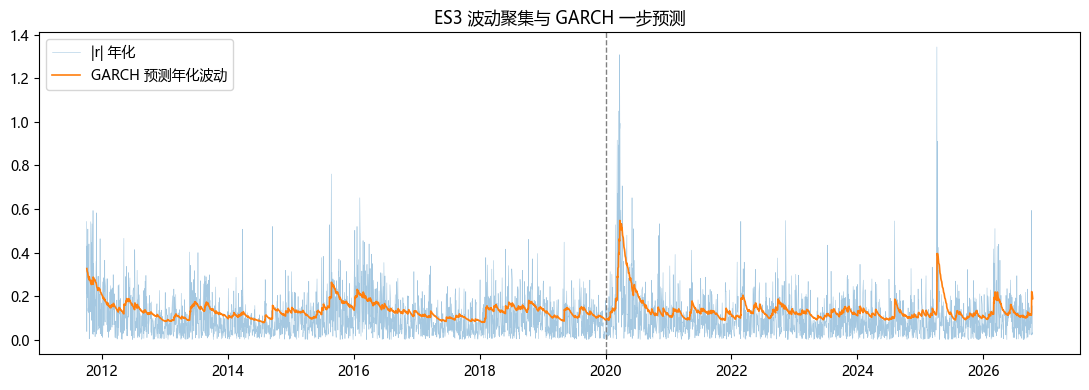

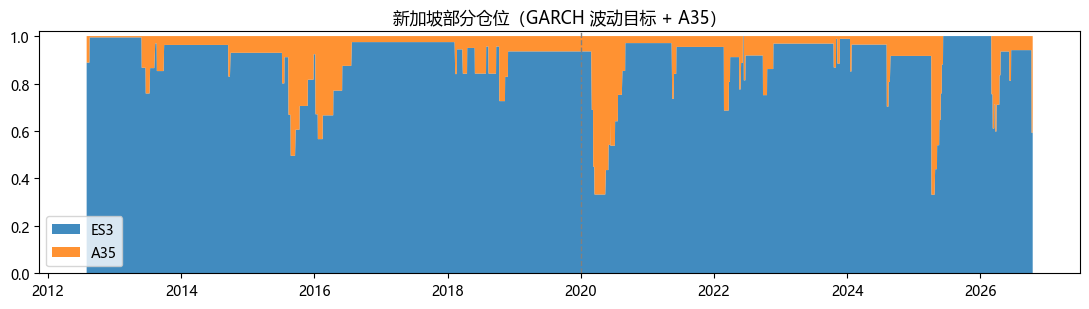

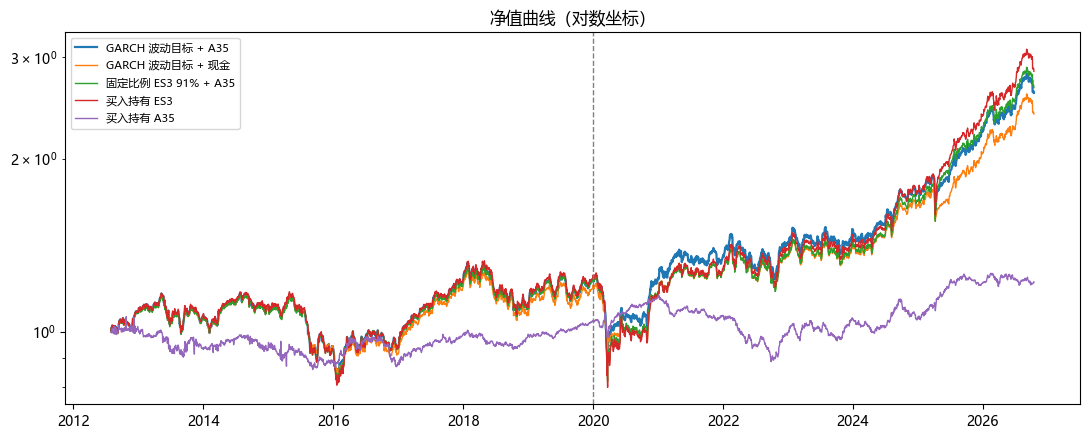

表格已保存到 E:\subjects\研一\Financial Econometrics\Project\Volumn-Rotation\results\tables
最新信号已保存到 E:\subjects\研一\Financial Econometrics\Project\Volumn-Rotation\results\signals\sti_latest_weight.csv

STI GARCH 流程完成。


In [ ]:
# ===== 只需修改这里，然后 Run All =====
DOWNLOAD = False        # 改为 True 下载 ES3.SI、A35.SI 与汇率（需 pip install yfinance），之后改回 False
CSV_PATH = None         # None = data/raw/sti_daily.csv
BASE_CCY = 'USD'        # 'USD'（与主策略同币种）或 'SGD'
REFIT = 'monthly'       # 'monthly' = 样本外每月扩展窗口重估；None = 冻结样本内参数
W_MAX = 1.0             # ES3 仓位上限（1 = 不加杠杆）
REBAL_BAND = 0.10       # 新旧仓位相差超过该值才调仓
COST_BPS = 10           # ES3 单边交易成本
BOND_COST_BPS = 10      # A35 单边交易成本
SAVE = True             # 保存表格、图和最新信号到 results/

results_sti = main(csv_path=CSV_PATH, download=DOWNLOAD, base_ccy=BASE_CCY, refit=REFIT,
                   w_max=W_MAX, band=REBAL_BAND, cost_bps=COST_BPS, bond_cost_bps=BOND_COST_BPS, save=SAVE)